In [1]:
import pandas as pd
import re
import shap
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.ensemble import StackingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.linear_model import SGDClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    confusion_matrix
)

In [2]:
df = pd.read_json(
    "../Data/reviews_Appliances.json",
    lines=True
)

df.head()

,reviewerID,asin,reviewerName,helpful,reviewText,overall,summary,unixReviewTime,reviewTime
0,A27HOWZBUBJ8FF,0970408285,Steve,"[0, 0]",Could have been longer though. well made and e...,4,Good fit,1387152000,"12 16, 2013"
1,A24HQ894NFSTF5,7301113188,"Maha Saqfalhait ""shopaholic! ;)""","[0, 0]",I like these containers so much i have ordered...,5,I Love the Freezer storage line..,1236902400,"03 13, 2009"
2,AXE83MK90ZEVZ,B00002N7HY,Strom,"[0, 0]","It works, no fires, etc. Why not 5 stars? Ho...",4,expectations achieved.,1389052800,"01 7, 2014"
3,A2J7X7ZIH2EWB1,B00002NATH,NaN,"[0, 0]",Fast shipping. Works great,5,Five Stars,1405814400,"07 20, 2014"
4,AJQFNOFTZ7GOX,B00002NATH,Barthbill,"[1, 1]",What can I say? It is the usual Leviton high q...,5,good product at a good price.,1277164800,"06 22, 2010"


In [3]:
df = df[['overall', 'reviewText']]

df = df.dropna()

df.columns = ['Score', 'Text']

df.head()

,Score,Text
0,4,Could have been longer though. well made and e...
1,5,I like these containers so much i have ordered...
2,4,"It works, no fires, etc. Why not 5 stars? Ho..."
3,5,Fast shipping. Works great
4,5,What can I say? It is the usual Leviton high q...


In [4]:
df = df.sample(10000, random_state=42)

df.shape

(10000, 2)

In [5]:
def convert_sentiment(score):

    if score <= 2:
        return 0

    elif score == 3:
        return 1

    else:
        return 2


df['Sentiment'] = df['Score'].apply(convert_sentiment)

df[['Score', 'Sentiment']].head()

,Score,Sentiment
108337,5,2
88460,5,2
143627,5,2
138805,5,2
129607,4,2


In [6]:
def clean_text(text):

    text = text.lower()

    text = re.sub(r'<.*?>', '', text)

    text = re.sub(r'[^a-zA-Z\s]', '', text)

    return text


df['Text'] = df['Text'].apply(clean_text)

df.head()

,Score,Text,Sentiment
108337,5,i have saved hundreds of dollars buying parts ...,2
88460,5,id be lost without these they really do captur...,2
143627,5,our front loading washing machine stopped pump...,2
138805,5,the product was just as described and so far i...,2
129607,4,this is sturdier than the cheap one that came ...,2


In [7]:
vectorizer = TfidfVectorizer(max_features=5000)

X = vectorizer.fit_transform(df['Text'])

y = df['Sentiment']

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [9]:
models = {

    "Logistic Regression":
    LogisticRegression(max_iter=1000),

    "Naive Bayes":
    MultinomialNB(),

    "SVM":
    LinearSVC()
}


for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print(name)

    print(
        "Accuracy:",
        accuracy_score(y_test, y_pred)
    )

    print("-----------------------")

Logistic Regression
Accuracy: 0.85
-----------------------
Naive Bayes
Accuracy: 0.79
-----------------------
SVM
Accuracy: 0.8495
-----------------------


In [10]:
base_models = [

    ("lr", LogisticRegression(max_iter=1000)),

    ("nb", MultinomialNB()),

    ("svm", LinearSVC())

]

meta_model = LogisticRegression()

stack_model = StackingClassifier(

    estimators=base_models,

    final_estimator=meta_model

)

stack_model.fit(X_train, y_train)

print("Stacking Model Trained")

Stacking Model Trained


In [11]:
y_pred = stack_model.predict(X_test)

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred)
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred
    )
)

print(
    "Macro F1:",
    f1_score(
        y_test,
        y_pred,
        average='macro'
    )
)

print(
    "Weighted F1:",
    f1_score(
        y_test,
        y_pred,
        average='weighted'
    )
)

Accuracy: 0.861

Classification Report:

              precision    recall  f1-score   support

           0       0.74      0.69      0.71       342
           1       0.55      0.05      0.09       123
           2       0.89      0.96      0.92      1535

    accuracy                           0.86      2000
   macro avg       0.72      0.57      0.58      2000
weighted avg       0.84      0.86      0.84      2000

Macro F1: 0.57518871737082
Weighted F1: 0.836367838118995


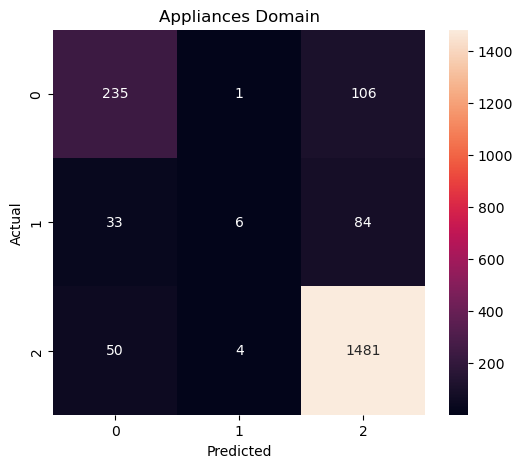

In [12]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d'
)

plt.title("Appliances Domain")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [13]:
sample = [
    "this washing machine is very bad and poor quality"
]

sample_vec = vectorizer.transform(sample)

prediction = stack_model.predict(sample_vec)

prediction

array([0])

In [14]:
shap.initjs()

In [15]:
X_train_dense = X_train.toarray()

X_test_dense = X_test.toarray()

In [16]:
shap_model = LogisticRegression(max_iter=1000)

shap_model.fit(
    X_train_dense,
    y_train
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [17]:
explainer = shap.Explainer(
    shap_model,
    X_train_dense
)

In [18]:
shap_values = explainer(
    X_test_dense[:100]
)

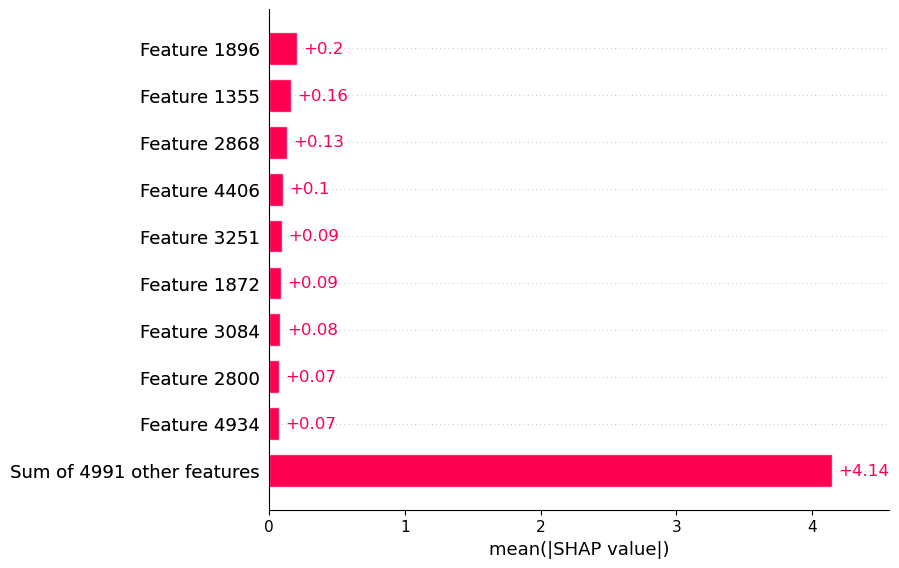

In [19]:
shap.plots.bar(
    shap_values[:, :, 2]
)

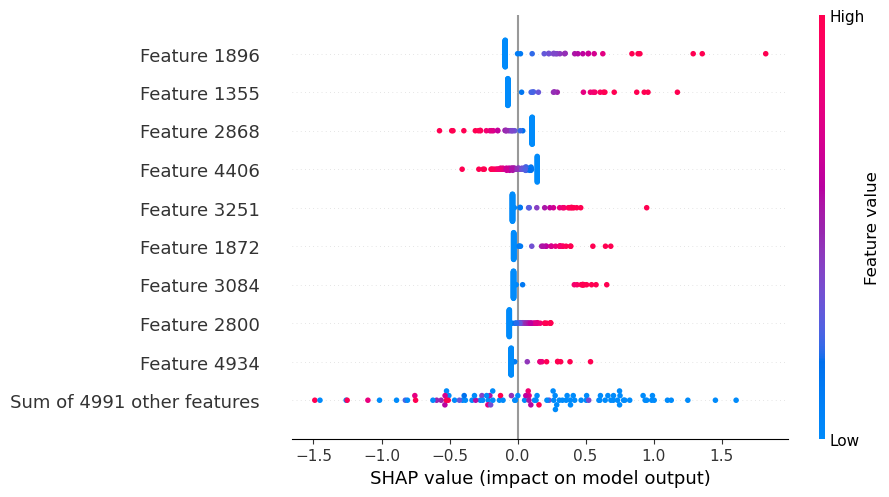

In [20]:
shap.plots.beeswarm(
    shap_values[:, :, 2]
)

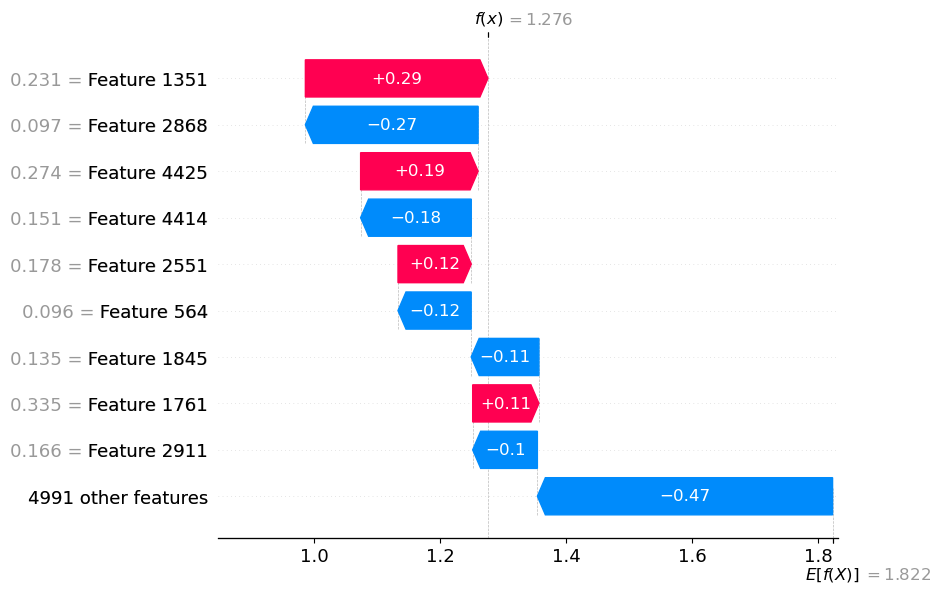

In [21]:
shap.plots.waterfall(
    shap_values[0, :, 2]
)